In [1]:
import sys
import time
import os
import copy
import gc
import importlib
import re
import math
import scipy
import pandas as pd
import pickle
import xarray as xr
import dask.array as da
import numpy as np
import xrft

from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, QuantileTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import explained_variance_score, r2_score, mean_squared_error
from sklearn.datasets import make_regression
from sklearn.utils import shuffle

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.colors import LogNorm
import xarray as xr
from cmcrameri import cm 

plt.style.use('../libs/notebookstyle_aps.mplstyle')

/home/b/b309252/turbulence-parameterization-palm/notebooks


## High resolution data and coarse graining, hor. cross sections

In [2]:
kwargs = {'decode_times':False,'chunks':'auto'}
ds_3d = xr.open_mfdataset('/work/bd1179/palm/JOBS_Lena/qml2a/OUTPUT/qml2a_3d.006.nc',**kwargs)
ts = xr.open_mfdataset('/work/bd1179/palm/JOBS_Lena/qml2a/OUTPUT/qml2a_ts.006.nc',**kwargs)
data_path = '/work/bd1179/b309252/QML2/QML2_a4_cg200_10z.txt'
df = pd.read_csv(data_path).dropna()

In [3]:
time_index = 0
z_index = 1

### load example cross-section of theta w
fine = ds_3d.isel(time = time_index, zw_3d = z_index*10+5).w*ds_3d.isel(time = 10, zu_3d = z_index*10+5).theta

### load coarse-grained cross-section, and SGS correction
coarse = df[(np.round(df.time) == np.round(ds_3d.time[time_index].values.item())) & (df.Z == z_index)].pivot(index = 'X', columns = 'Y', values = 'theta_w_cg')
sgs = - df[(np.round(df.time) == np.round(ds_3d.time[time_index].values.item())) & (df.Z == z_index)].pivot(index = 'X', columns = 'Y', values = 'theta_w_SGS')

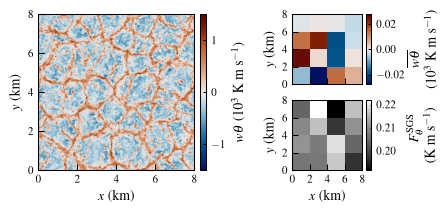

In [4]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

x = np.arange(0, 9)
y = np.arange(0, 9)

# ---------- layout, numbers in inches ----------
s   = 0.70                 # side of the small square panels
dy  = 0.16                 # vertical gap between the small panels
sL  = 2 * s + dy           # side of the large panel (spans both rows) -> 1.56
g0  = 0.06                 # gap: large panel | its colorbar (label room)
cw0 = 0.06                 # width of the large colorbar
gx  = 0.36 +0.5                 # gap: large colorbar | right column
g1  = 0.04                 # gap: small panels | their colorbars
cw  = 0.05                 # width of the small colorbars
mL, mR = 0.44, 0.18        # left / right margins
mT, mB = 0.12, 0.45        # top / bottom margins

fig_w = mL + sL + g0 + cw0 + gx + s + g1 + cw + mR   # = 3.5 in
fig_h = mT + s + dy + s + mB                          # = 2.13 in
fig = plt.figure(figsize=(fig_w, fig_h))
fig.subplots_adjust(left=mL / fig_w, right=1 - mR / fig_w,
                    bottom=mB / fig_h, top=1 - mT / fig_h)

gs = GridSpec(3, 7, figure=fig,
              width_ratios=[sL, g0, cw0, gx, s, g1, cw],
              height_ratios=[s, dy, s],
              wspace=0, hspace=0)

ax_large = fig.add_subplot(gs[0:3, 0])
ax_cbar0 = fig.add_subplot(gs[0:3, 2])
ax_top    = fig.add_subplot(gs[0, 4])
ax_cbar1  = fig.add_subplot(gs[0, 6])
ax_bottom = fig.add_subplot(gs[2, 4], sharex=ax_top, sharey=ax_top)
ax_cbar2  = fig.add_subplot(gs[2, 6])

vm = np.max(np.abs(fine.values / 1e3))
im0 = ax_large.imshow(fine / 1e3, origin='lower', cmap=cm.vik, aspect='equal',
                      vmin=-vm, vmax=vm, extent=[x.min(), x.max(), y.min(), y.max()])
ax_large.set_xlabel("$x$ (km)")
ax_large.set_ylabel("$y$ (km)")

vm = np.max(np.abs(coarse / 1e3))
im1 = ax_top.imshow(coarse / 1e3, origin='lower', cmap=cm.vik, aspect='equal',
                    vmin=-vm, vmax=vm, extent=[x.min(), x.max(), y.min(), y.max()])
ax_top.set_ylabel("$y$ (km)")
ax_top.set_xticks(np.arange(0, 9, 2))
ax_top.set_yticks(np.arange(0, 9, 2))
ax_top.tick_params(labelbottom=False)

vm = np.max(np.abs(sgs))
im2 = ax_bottom.imshow(sgs, origin='lower', cmap=cm.grayC, aspect='equal',
                       extent=[x.min(), x.max(), y.min(), y.max()])
ax_bottom.set_xlabel("$x$ (km)")
ax_bottom.set_ylabel("$y$ (km)")
ax_bottom.set_xticks(np.arange(0, 9, 2))
ax_bottom.set_yticks(np.arange(0, 9, 2))

cbar0 = fig.colorbar(im0, cax=ax_cbar0)
cbar0.set_label(r"$w\theta$ ($10^{3}$ K m s$^{-1}$)")
cbar0.set_ticks([-1, 0, 1])
cbar0.ax.tick_params(which="major", length=2)
cbar1 = fig.colorbar(im1, cax=ax_cbar1)
cbar1.set_label(r"$\overline{w\theta}$ \\ ($10^{3}$ K m s$^{-1}$)", labelpad = 2)
cbar1.ax.tick_params(which="major", length=2)
cbar2 = fig.colorbar(im2, cax=ax_cbar2)
cbar2.set_label(r"$F_{\theta}^{\rm SGS}$ \\ (K m s$^{-1}$)",  labelpad = 7.4)
cbar2.set_ticks(ticks=[0.2,0.21,0.22])
cbar2.ax.tick_params(which="major", length=1)

fig.savefig('./figures/coarse_graining.pdf', bbox_inches='tight')

## Altitude dependence and energy spectra

In [5]:
from dask_jobqueue import SLURMCluster
from dask.distributed import Client
from dask.diagnostics import ProgressBar

In [6]:
# we first need to calculate a common grid for all variables, because in PALM, the staggered grid is different for velocities
def make_same_coords(ds, grid = 'theta',**interp_kwargs):
    
    if grid == 'theta':
        u1 = ds.u.interp(xu = ds.x.values,**interp_kwargs)
        v1 = ds.v.interp(yv = ds.y.values,**interp_kwargs)
        w1 = ds.w.interp(zw_3d = ds.zu_3d.values,**interp_kwargs)

        u1 = u1.rename({'xu':'x'})
        v1 = v1.rename({'yv':'y'})
        w1 = w1.rename({'zw_3d':'zu_3d'})
        
        ds['u1'] = u1
        ds['v1'] = v1
        ds['w1'] = w1
    
    elif grid == 'velocities':
        thu = ds.theta.interp(x = ds.xu.values,**interp_kwargs)
        thv = ds.theta.interp(y = ds.yv.values,**interp_kwargs)
        thw = ds.theta.interp(zu_3d = ds.zw_3d.values,**interp_kwargs)

        thu = thu.rename({'x':'xu'})
        thv = thv.rename({'y':'yv'})
        thw = thw.rename({'zu_3d':'zw_3d'})
        
        ds['thu'] = thu
        ds['thv'] = thv
        ds['thw'] = thw

    return ds

def compute_energy(ds):
    
    Uhat = xrft.fft(ds.u1i, dim = {'x','y','zu_3d'})
    Vhat = xrft.fft(ds.v1i, dim = {'x','y','zu_3d'})
    What = xrft.fft(ds.w1i, dim = {'x','y','zu_3d'})
    
    energy_density = 0.5*(np.abs(Uhat)**2 + np.abs(Vhat)**2 + np.abs(What)**2)
   
    k3d = xr.apply_ufunc(lambda x,y,z: np.sqrt(x**2 + y**2 +z**2),energy_density.freq_zu_3d, energy_density.freq_y, energy_density.freq_x)
    k3d.name = 'k3d'
    k3d = k3d.reindex_like(energy_density)
    energy_density_3d = xr.Dataset({'Ek3d':energy_density}).merge(k3d.chunk('auto'))
    energy_density_3d = energy_density_3d.unify_chunks()
    
    return energy_density_3d
    
def make_bins(energy_density, num = 50, log = True):
    
    freq_x_abs = xr.apply_ufunc(np.abs,energy_density.freq_x,dask = 'parallelized')
    kmin_x = np.min(freq_x_abs[freq_x_abs > 0])
    kmax_x = np.max(freq_x_abs)

    freq_y_abs = xr.apply_ufunc(np.abs,energy_density.freq_y,dask = 'parallelized')
    kmin_y = np.min(freq_y_abs[freq_y_abs > 0])
    kmax_y = np.max(freq_y_abs)

    freq_zu_3d_abs = xr.apply_ufunc(np.abs,energy_density.freq_zu_3d,dask = 'parallelized')
    kmin_zu_3d = np.min(freq_zu_3d_abs[freq_zu_3d_abs > 0])
    kmax_zu_3d = np.max(freq_zu_3d_abs)
    
    # Bin the energy density in radial wavenumber bins
    kmin = np.min([kmin_y, kmin_x, kmin_zu_3d])
    kmax = np.max([kmax_y, kmax_x, kmax_zu_3d])

    if not log:
        kbinedges = np.linspace(kmin,kmax,num)
        kbin_centers = 0.5*(kbinedges[:-1] + kbinedges[1:])
    else:
        kbinedges = np.logspace(np.log10(kmin), np.log10(kmax), num=num)
        kbin_centers = np.sqrt(kbinedges[:-1] * kbinedges[1:]) 
    return kbinedges, kbin_centers

def calc_spectrum(energy_density_3d, numbins = 50, log = True):
    
    # bins in log scale
    log_kbinedges, kbin_centers = make_bins(energy_density_3d, num = numbins, log = log)
    
    mode_count, _ = dd.array.histogram(energy_density_3d.k3d, bins = log_kbinedges)
    spectrum, _ = dd.array.histogram(energy_density_3d.k3d, weights = energy_density_3d.Ek3d,  bins = log_kbinedges)

    # compute histogram
    mode_count_array = mode_count.compute()
    spectrum_array = spectrum.compute()

    # avoid division by zero
    non_zero_modes = mode_count_array > 0
    spectrum_array[non_zero_modes] /= mode_count_array[non_zero_modes]

    k = kbin_centers[non_zero_modes]
    Ek = spectrum_array[non_zero_modes]
    
    return Ek,k

In [7]:
######### versions for cluster

def make_same_coords(ds, grid='theta', **interp_kwargs):
    """Interpolates fields to the same coordinate grid."""
    if grid == 'theta':
        u1 = ds.u.interp(xu=ds.x.values, **interp_kwargs).rename({'xu': 'x'})
        v1 = ds.v.interp(yv=ds.y.values, **interp_kwargs).rename({'yv': 'y'})
        w1 = ds.w.interp(zw_3d=ds.zu_3d.values, **interp_kwargs).rename({'zw_3d': 'zu_3d'})
        ds['u1'], ds['v1'], ds['w1'] = u1, v1, w1

    elif grid == 'velocities':
        thu = ds.theta.interp(x=ds.xu.values, **interp_kwargs).rename({'x': 'xu'})
        thv = ds.theta.interp(y=ds.yv.values, **interp_kwargs).rename({'y': 'yv'})
        thw = ds.theta.interp(zu_3d=ds.zw_3d.values, **interp_kwargs).rename({'zu_3d': 'zw_3d'})
        ds['thu'], ds['thv'], ds['thw'] = thu, thv, thw

    return ds


def compute_energy(ds):
    """Compute 3D spectral energy density with correct chunking for FFT."""
    # rechunk so ffts are in one chunk
    ds = ds.chunk({'x': -1, 'y': -1, 'zu_3d': -1})

    Uhat = xrft.fft(ds.u1i, dim={'x', 'y', 'zu_3d'})
    Vhat = xrft.fft(ds.v1i, dim={'x', 'y', 'zu_3d'})
    What = xrft.fft(ds.w1i, dim={'x', 'y', 'zu_3d'})

    Ek3d = 0.5 * (np.abs(Uhat)**2 + np.abs(Vhat)**2 + np.abs(What)**2)

    fx = Ek3d.coords.get('freq_x', None)
    fy = Ek3d.coords.get('freq_y', None)
    fz = Ek3d.coords.get('freq_zu_3d', Ek3d.coords.get('freq_z', None))

    if fx is None or fy is None or fz is None:
        raise RuntimeError(f"Could not find expected frequency coords. Found: {list(Ek3d.coords)}")

    k3d = xr.apply_ufunc(
        lambda x, y, z: np.sqrt(x**2 + y**2 + z**2),
        fx, fy, fz
    )
    k3d.name = 'k3d'

    energy_density_3d = xr.Dataset({'Ek3d': Ek3d, 'k3d': k3d}).unify_chunks()
    return energy_density_3d



def make_bins(energy_density, num=50, log=True):
    """Construct logarithmic or linear bin edges."""
    freq_x_abs = np.abs(energy_density.freq_x)
    freq_y_abs = np.abs(energy_density.freq_y)
    freq_z_abs = np.abs(energy_density.freq_zu_3d)

    kmin = np.min([freq_x_abs[freq_x_abs > 0].min(),
                   freq_y_abs[freq_y_abs > 0].min(),
                   freq_z_abs[freq_z_abs > 0].min()])
    kmax = np.max([freq_x_abs.max(), freq_y_abs.max(), freq_z_abs.max()])

    print(kmin, kmax)
    
    if log:
        kbinedges = np.logspace(np.log10(kmin), np.log10(kmax), num=num)
        kcenters = np.sqrt(kbinedges[:-1] * kbinedges[1:])
    else:
        kbinedges = np.linspace(kmin, kmax, num=num)
        kcenters = 0.5 * (kbinedges[:-1] + kbinedges[1:])

    return kbinedges, kcenters


def calc_spectrum_from_ds(ed_ds, numbins=50, log=True):
    """Compute isotropic energy spectrum."""
    
    k3d = ed_ds.k3d.data
    Ek3d = ed_ds.Ek3d.data

    if not isinstance(k3d, da.Array):
        k3d = da.from_array(k3d, chunks='auto')
    if not isinstance(Ek3d, da.Array):
        Ek3d = da.from_array(Ek3d, chunks='auto')

    k3d = k3d.ravel()
    Ek3d = Ek3d.ravel()

    if k3d.chunks != Ek3d.chunks:
        k3d = k3d.rechunk(chunks='auto')
        Ek3d = Ek3d.rechunk(chunks=k3d.chunks)

    k3d = k3d.persist()
    Ek3d = Ek3d.persist()
    k3d = k3d.compute_chunk_sizes()
    Ek3d = Ek3d.compute_chunk_sizes()

    freq_min = np.nanmin(k3d[k3d > 0].compute())
    freq_max = np.nanmax(k3d.compute())

    if log:
        kbinedges = np.logspace(np.log10(freq_min), np.log10(freq_max), num=numbins)
    else:
        kbinedges = np.linspace(freq_min, freq_max, numbins)
    kbin_centers = 0.5 * (kbinedges[:-1] + kbinedges[1:])

    counts_da, _ = da.histogram(k3d, bins=kbinedges)
    weighted_da, _ = da.histogram(k3d, bins=kbinedges, weights=Ek3d)

    counts = counts_da.compute()
    weighted = weighted_da.compute()

    n = min(len(counts), len(weighted), len(kbin_centers))
    counts, weighted, kbin_centers = counts[:n], weighted[:n], kbin_centers[:n]

    nonzero = counts > 0
    Ek = np.zeros_like(weighted)
    Ek[nonzero] = weighted[nonzero] / counts[nonzero]

    k = kbin_centers[nonzero]
    Ek = Ek[nonzero]

    return Ek, k




### spectra figure panel

In [14]:
myred = cm.berlin(0.8)
myblue = cm.berlin(0.2)

def plot_spectra(ax, s = 'a4_', xx = 0, yy = 0, colors = [myblue, myred]):
    
    tts = range(1, 11)
    
    
    norm = 1 / 1e9
    norm2 = 1 / 600**3

    Ek_global = []
    Ek_sub = []
    
    for tt in tts:
        sp = pd.read_csv(
            f'./spectra/{s}global_spectrum_t{tt}_bins80_X{xx}_Y{yy}.txt'
        )
        k = 2 * np.pi * sp.k.values
        Ek_global.append(norm * sp.Ek.values * k**2 * 4*np.pi)
    
        
        sp2 = pd.read_csv(
            f'./spectra/{s}200to800_spectrum_t{tt}_bins80_X{xx}_Y{yy}.txt'
        )
        k2 = 2 * np.pi * sp2.k.values
        Ek_sub.append(norm2 * sp2.Ek.values * k2**2 * 4*np.pi)
    
    Ek_global = np.array(Ek_global)
    Ek_sub = np.array(Ek_sub)
    
    log_Ek_g = np.log(Ek_global)
    log_Ek_s = np.log(Ek_sub)
    
    Ek_g_mean = np.exp(log_Ek_g.mean(axis=0))
    Ek_g_lo   = np.exp(log_Ek_g.mean(axis=0) - log_Ek_g.std(axis=0))
    Ek_g_hi   = np.exp(log_Ek_g.mean(axis=0) + log_Ek_g.std(axis=0))
    
    Ek_s_mean = np.exp(log_Ek_s.mean(axis=0))
    Ek_s_lo   = np.exp(log_Ek_s.mean(axis=0) - log_Ek_s.std(axis=0))
    Ek_s_hi   = np.exp(log_Ek_s.mean(axis=0) + log_Ek_s.std(axis=0))
    

    
    ax.loglog(k, Ek_g_mean, color=colors[0], label = '$[0, z_{\\rm ABL}]$')
    ax.fill_between(
        k, Ek_g_lo, Ek_g_hi,
        color=colors[0], alpha=0.3
    )
    
    ax.loglog(k2, Ek_s_mean, color=colors[1], label = '$[0.2 z_{\\rm ABL}, 0.8 z_{\\rm ABL}]$')
    ax.fill_between(
        k2, Ek_s_lo, Ek_s_hi,
        color=colors[1], alpha=0.3
    )
    
    # −5/3 Kolmogorov law
    kref = k[2:-3]
    ax.loglog(
        kref,
        2*Ek_g_mean[0] * (kref / kref[0])**(-5/3),
        'k--'
    )

    ax.set_ylim(5, 1e5)
    ax.set_xlabel(r'$k\;(\mathrm{m^{-1}})$')
    ax.set_ylabel(r'$E(k)\;(\mathrm{m^{3}\,s^{-2}})$')
    #ax.legend()

### vertical profiles

In [7]:
df_all = pd.read_csv('./Smagorinsky_a4.txt')
df_all['SGS'] = - df_all.theta_w_SGS

df_all2 = pd.read_csv('./Smagorinsky_c4.txt')
df_all2['SGS'] = - df_all2.theta_w_SGS

In [8]:
def plot_var_density(ax, df_all, variable, n_steps = 22,  cmap=cm.oslo_r,shading = True, color = 'k', ls = '-'):

    df_all['z_mean'] = np.round(df_all.zrel_u * n_steps) / n_steps
    grouped = df_all.groupby('z_mean')[variable].mean()

    x = df_all[variable].values
    y = df_all['zrel_u'].values

    if shading:
        h = ax.hist2d(
            x, y, bins=50, cmap=cmap, norm=LogNorm(vmin = 1, vmax = 1e6),  # remove LogNorm() if you prefer linear
        )
    ax.plot(grouped.values, grouped.index, lw=1.5, color = color, linestyle = ls)

    ax.set_ylabel(r'$z/z_{\rm ABL}$')
    ax.set_xlabel(variable)
    
    if shading:
        return h  # handle for colorbar
    else:
        return

def plot_var_range(ax, df_all, variable, n_steps=22, shading=True, label = None, color='k', linestyle = '-', alpha=0.2):
    df_all = df_all.copy()  # avoid mutating the caller's frame
    df_all['z_mean'] = np.round(df_all.Z * n_steps) / n_steps*100
    grouped = df_all.groupby('z_mean')

    x_mean = grouped[variable].mean()
    x_min  = grouped[variable].min()
    x_max  = grouped[variable].max()

    if shading:
        ax.fill_betweenx(x_mean.index, x_min.values, x_max.values,
                         color=color, alpha=alpha, linewidth=0,
                         zorder=1)  # drawn first so the line sits on top

    ax.plot(x_mean.values, x_mean.index, lw=1.5, color=color, linestyle=linestyle, zorder=2, label = label)
    ax.set_ylabel(r'$z (m)$')
    ax.set_xlabel(variable)

    return None


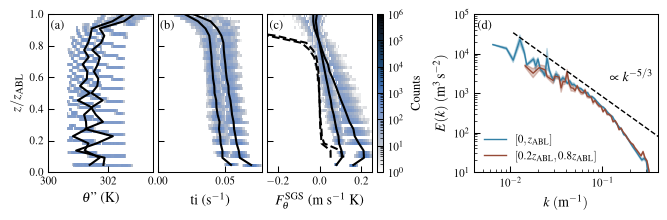

In [9]:
fig = plt.figure(figsize=(6.77, 6.77/3))

outer = GridSpec(
    1, 2,
    width_ratios=[2., 1.1],
    wspace=0.35
)

inner = GridSpecFromSubplotSpec(
    1, 4,
    subplot_spec=outer[0],
    width_ratios=[1, 1, 1, 0.06],
    wspace=0.06 
)

ax1 = fig.add_subplot(inner[0])
ax2 = fig.add_subplot(inner[1], sharey=ax1)
ax3 = fig.add_subplot(inner[2], sharey=ax1)
cax = fig.add_subplot(inner[3])
ax4 = fig.add_subplot(outer[1])

for ax, lab in zip([ax1, ax2, ax3, ax4], ["(a)", "(b)", "(c)", "(d)"]):
    ax.text(
        0.02, 0.96, lab,
        transform=ax.transAxes,
        va="top", ha="left",
        fontsize=9
    )

for dfx in [df_all, df_all2]:
    h1 = plot_var_density(ax1, dfx, 'theta')
    ax1.set_xlabel(r'$\theta$" (K)')
    ax1.set_ylabel(r'$z / z_\mathrm{ABL}$')
    ax1.set_xlim(300,303.5)
    
    h2 = plot_var_density(ax2, dfx, 'ti')
    ax2.set_xlabel(r'ti (s$^{-1}$)')
    ax2.set_ylabel(r'$z / z_\mathrm{ABL}$')
    
    
    h3 = plot_var_density(ax3, dfx, 'SGS')
    plot_var_density(
        ax3, dfx, 'Ftheta_z',
        shading=False, color='k', ls='--'
    )
    
    ax3.set_xlabel(r'$F_{\theta}^{\rm SGS}$ (m s$^{-1}$ K)')
    ax3.set_xlim(-0.25, 0.25)
    #ax3.axvline(0)
    for ax in [ax2, ax3]:
        ax.set_ylabel('')
        ax.tick_params(labelleft=False)
    for ax in [ax1, ax2, ax3]:
        ax.set_ylim(0,1.0)
    ax2.set_xlim(0,)


cbar = fig.colorbar(
    h2[3], cax=cax, orientation='vertical'
)
cbar.set_label(
    'Counts',
    fontsize=9,
    rotation=90,
    labelpad=6
)
cbar.ax.tick_params(labelsize=8)


plot_spectra(ax4, xx=3, yy=3)
ax4.set_xlim(4e-3, 4e-1)
ax4.set_ylim(10, 1e5)
ax4.text(0.12,2e3,'$\propto k^{-5/3}$')

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.22,
    top=0.92
)



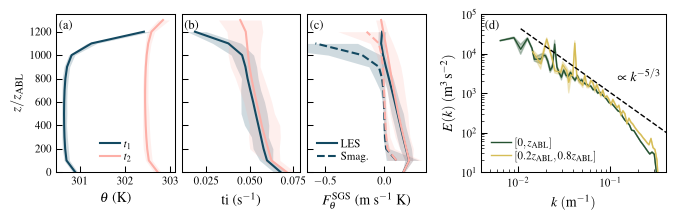

In [26]:
fig = plt.figure(figsize=(6.77, 6.77/3))#, constrained_layout=True)

c1 = cm.batlow(0.15)
c2 = cm.batlow(0.85)

c3 = cm.bamako(0.25)
c4 = cm.bamako(0.85)

outer = GridSpec(
    1, 2,
    width_ratios=[2, 1],
    wspace=0.2
)

inner = GridSpecFromSubplotSpec(
    1, 3,
    subplot_spec=outer[0],
    width_ratios=[1, 1, 1],
    wspace=0.06 
)

ax1 = fig.add_subplot(inner[0])
ax2 = fig.add_subplot(inner[1], sharey=ax1)
ax3 = fig.add_subplot(inner[2], sharey=ax1)
ax4 = fig.add_subplot(outer[1])

for ax, lab in zip([ax1, ax2, ax3, ax4], ["(a)", "(b)", "(c)", "(d)"]):
    ax.text(
        0.02, 0.96, lab,
        transform=ax.transAxes,
        va="top", ha="left",
        fontsize=9
    )

cols = [c1, c2]
ls = ['--','--']
labels = ['$t_1$', '$t_2$']
legend_kwargs = {"handlelength": 1.8, "handletextpad": 0.3, "labelspacing": 0.2}
i = 0
for dfx in [df_all[df_all.time < df_all.time.unique()[10]], df_all[df_all.time > df_all.time.unique()[-10]]]:#df_all2[df_all2.time < df_all2.time.unique()[10]]]:
    h1 = plot_var_range(ax1, dfx, 'theta', color = cols[i], label = labels[i])
    ax1.set_xlabel(r'$\theta$ (K)')
    ax1.set_ylabel(r'$z / z_\mathrm{ABL}$')
    ax1.legend(**legend_kwargs)
    
    h2 = plot_var_range(ax2, dfx, 'ti', color = cols[i])
    ax2.set_xlabel(r'ti (s$^{-1}$)')
    ax2.set_ylabel(r'$z / z_\mathrm{ABL}$')
    #ax2.set_xlim(0,0.1)
    
    
    h3 = plot_var_range(ax3, dfx, 'SGS', color = cols[i], label = 'LES'if (i == 0)else None)
    plot_var_range(ax3, dfx, 'Ftheta_z',color = cols[i], linestyle = ls[i], label = 'Smag.'if (i == 0)else None)
    
    ax3.set_xlabel(r'$F_{\theta}^{\rm SGS}$ (m s$^{-1}$ K)')
    ax3.set_xlim(-0.65, 0.35)
    #ax3.axvline(0)
    for ax in [ax2, ax3]:
        ax.set_ylabel('')
        ax.tick_params(labelleft=False)
    for ax in [ax1, ax2, ax3]:
        ax.set_ylim(0,1350)
    i+= 1
ax3.legend(**legend_kwargs)

plot_spectra(ax4, xx=2, yy=2, colors = [c3, c4])
ax4.set_xlim(4e-3, 4e-1)
ax4.set_ylim(10, 1e5)
ax4.text(0.12,2e3,'$\propto k^{-5/3}$')
ax4.legend(**legend_kwargs)

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.22,
    top=0.92
)

fig.savefig('./figures/vertical_profiles_cascades.pdf')
